Name: Gayatri Kakde
Roll no: 4337
Subject: Deep Learning

In [2]:
# Download the Dataset
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/cifar10.tgz

In [3]:
# Extract the Dataset
!mkdir -p /content/data
!tar -xzf cifar10.tgz -C /content/data

In [4]:
# Check the Dataset Folders
!ls /content/data/cifar10

test  train


In [5]:
# Import Required Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

In [6]:
# Define Dataset Paths
train_dir = "/content/data/cifar10/train"
test_dir = "/content/data/cifar10/test"

In [7]:
# Initialize Image Data Generators
train_datagen = ImageDataGenerator(rescale=1.0 / 255)
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

In [8]:
# Load Training Images
train_batch_size = 5000

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(32, 32),
    batch_size=train_batch_size,
    class_mode='categorical'
)

Found 50000 images belonging to 10 classes.


In [9]:
# Load Testing Images
test_batch_size = 1000

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(32, 32),
    batch_size=test_batch_size,
    class_mode='categorical'
)

Found 10000 images belonging to 10 classes.


In [10]:
# Extract Training and Testing Data
x_train, y_train = train_generator[0]
x_test, y_test = test_generator[0]

print(len(x_train))
print(len(x_test))

5000
1000


In [11]:
# Load the Pretrained VGG16 Model
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(32, 32, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [12]:
# Freeze the Base Model Layers
for layer in base_model.layers:
    layer.trainable = False

In [13]:
# Add Custom Classification Layers
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)

predictions = Dense(10, activation='softmax')(x)

In [15]:
# Build the Final Model
model = Model(
    inputs=base_model.input,
    outputs=predictions
)

In [17]:
# Compile the Model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
# Train the Model
model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=10,
    validation_data=(x_test, y_test)
)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 76s 939ms/step - accuracy: 0.2914 - loss: 1.9621 - val_accuracy: 0.3980 - val_loss: 1.6572
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 71s 806ms/step - accuracy: 0.4410 - loss: 1.5819 - val_accuracy: 0.4640 - val_loss: 1.5026
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 91s 918ms/step - accuracy: 0.4920 - loss: 1.4415 - val_accuracy: 0.4840 - val_loss: 1.4496
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 64s 806ms/step - accuracy: 0.5186 - loss: 1.3596 - val_accuracy: 0.5070 - val_loss: 1.3936
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 92s 932ms/step - accuracy: 0.5428 - loss: 1.2871 - val_accuracy: 0.5100 - val_loss: 1.3915
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 73s 928ms/step - accuracy: 0.5686 - loss: 1.2394 - val_accuracy: 0.5370 - val_loss: 1.3468
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 82s 929ms/step - accuracy: 0.5752 - loss: 1.1915 - val_accuracy: 0.5300 - val_loss: 1.3554
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 63s 796ms/step - accuracy: 0.6016 - loss: 1.1446 - val_accu

In [19]:
# Predict Test Images
import matplotlib.pyplot as plt

predicted_value = model.predict(x_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 312ms/step


In [20]:
# Display Class Labels
labels = list(test_generator.class_indices.keys())
print(labels)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Predicted: cat
Actual: deer


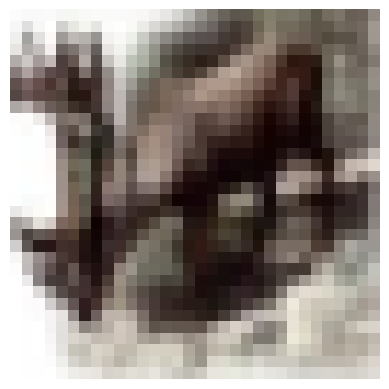

In [21]:
# Display Prediction for Image 890
n = 890

plt.imshow(x_test[n])
plt.axis('off')

print("Predicted:", labels[np.argmax(predicted_value[n])])
print("Actual:", labels[np.argmax(y_test[n])])

Predicted: cat
Actual: cat


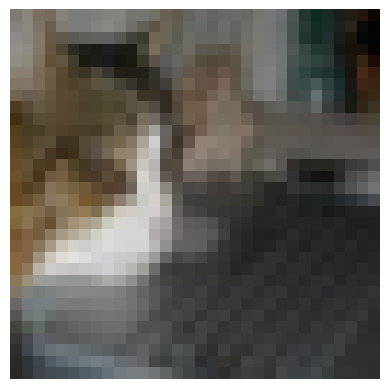

In [22]:
# Display Prediction for Image 590
n = 590

plt.imshow(x_test[n])
plt.axis('off')

print("Predicted:", labels[np.argmax(predicted_value[n])])
print("Actual:", labels[np.argmax(y_test[n])])

Predicted: airplane
Actual: airplane


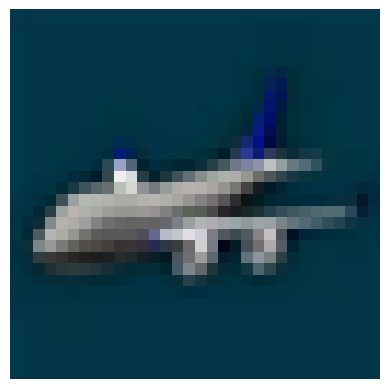

In [23]:
# Display Prediction for Image 600
n = 600

plt.imshow(x_test[n])
plt.axis('off')

print("Predicted:", labels[np.argmax(predicted_value[n])])
print("Actual:", labels[np.argmax(y_test[n])])